In [1]:
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import os

print("Current folder:", os.getcwd())
print("\nAvailable datasets:")

for root, dirs, files in os.walk("."):
    for file in files:
        if file.endswith((".csv", ".xlsx")):
            print(os.path.join(root, file))

Current folder: c:\Users\sam\OneDrive\Documents\E-Commerce_Customer_Retention_Analytics\06_Documentation

Available datasets:


In [3]:
from pathlib import Path

project_folder = Path.cwd().parent

print("Project folder:", project_folder)
print("\nAvailable datasets:")

for file in project_folder.rglob("*"):
    if file.suffix.lower() in [".csv", ".xlsx"]:
        print(file.relative_to(project_folder))

Project folder: c:\Users\sam\OneDrive\Documents\E-Commerce_Customer_Retention_Analytics

Available datasets:
01_Raw_Data\Online Retail.xlsx
02_Cleaned_Data\Online Retail.xlsx
02_Cleaned_Data\Online_Retail_Cleaned_Sample.csv
02_Cleaned_Data\Online_Retail_Python_Cleaned.csv
03_Python\rfm_customer_metrics.csv
03_Python\rfm_customer_segments.csv
03_Python\rfm_top_10_vip.csv
03_Python\rfm_vip_customers.csv
03_Python\rfm_vip_revenue_summary.csv
04_Validation_Reports\duplicate_orders.csv
04_Validation_Reports\revenue_discrepancies.csv
04_Validation_Reports\validation_summary.csv
08_Discount_Analysis\campaign_comparison.csv
08_Discount_Analysis\discount_sensitivity_results.csv


In [4]:
import pandas as pd
from pathlib import Path

# Locate the main project folder
project_folder = Path.cwd().parent

# Load cleaned sales data
file_path = project_folder / "02_Cleaned_Data" / "Online_Retail_Python_Cleaned.csv"

df = pd.read_csv(file_path)

# Display dataset information
print("Dataset loaded successfully!")
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Total rows: 392692
Total columns: 9

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [5]:
print("Dataset columns:")
for column in df.columns:
    print(column)

print("\nDataset information:")
df.info()

Dataset columns:
InvoiceNo
StockCode
Description
Quantity
InvoiceDate
UnitPrice
CustomerID
Country
Revenue

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 392692 entries, 0 to 392691
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    392692 non-null  int64  
 1   StockCode    392692 non-null  str    
 2   Description  392692 non-null  str    
 3   Quantity     392692 non-null  int64  
 4   InvoiceDate  392692 non-null  str    
 5   UnitPrice    392692 non-null  float64
 6   CustomerID   392692 non-null  int64  
 7   Country      392692 non-null  str    
 8   Revenue      392692 non-null  float64
dtypes: float64(2), int64(3), str(4)
memory usage: 27.0 MB


In [6]:
# Check required columns
required_columns = [
    "Quantity",
    "UnitPrice",
    "InvoiceNo",
    "InvoiceDate"
]

missing = [col for col in required_columns if col not in df.columns]

if missing:
    print("Missing columns:", missing)
    print("Available columns:", df.columns.tolist())
else:
    # Convert to numeric values
    df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
    df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

    # Exclude returns and invalid sales
    sales_df = df[
        (df["Quantity"] > 0) &
        (df["UnitPrice"] > 0) &
        (~df["InvoiceNo"].astype(str).str.startswith("C"))
    ].copy()

    # Calculate revenue
    sales_df["Revenue"] = (
        sales_df["Quantity"] * sales_df["UnitPrice"]
    )

    total_revenue = sales_df["Revenue"].sum()
    total_orders = sales_df["InvoiceNo"].nunique()
    total_units = sales_df["Quantity"].sum()
    average_order_value = total_revenue / total_orders if total_orders else 0

    print("SALES PERFORMANCE KPIs")
    print("----------------------")
    print(f"Total Revenue: £{total_revenue:,.2f}")
    print(f"Total Orders: {total_orders:,}")
    print(f"Total Units Sold: {total_units:,.0f}")
    print(f"Average Order Value: £{average_order_value:,.2f}")

SALES PERFORMANCE KPIs
----------------------
Total Revenue: £8,887,208.89
Total Orders: 18,532
Total Units Sold: 5,152,002
Average Order Value: £479.56


In [7]:
# Identify top 10 products by revenue

top_products = (
    sales_df.groupby("Description")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum")
    )
    .sort_values("Total_Revenue", ascending=False)
    .head(10)
    .reset_index()
)

print("TOP 10 SELLING PRODUCTS")
display(top_products)

TOP 10 SELLING PRODUCTS


,Description,Total_Revenue,Units_Sold
0,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
1,REGENCY CAKESTAND 3 TIER,142264.75,12374
2,WHITE HANGING HEART T-LIGHT HOLDER,100392.10,36706
3,JUMBO BAG RED RETROSPOT,85040.54,46078
4,MEDIUM CERAMIC TOP STORAGE JAR,81416.73,77916
5,POSTAGE,77803.96,3120
6,PARTY BUNTING,68785.23,15279
7,ASSORTED COLOUR BIRD ORNAMENT,56413.03,35263
8,Manual,53419.93,6933
9,RABBIT NIGHT LIGHT,51251.24,27153


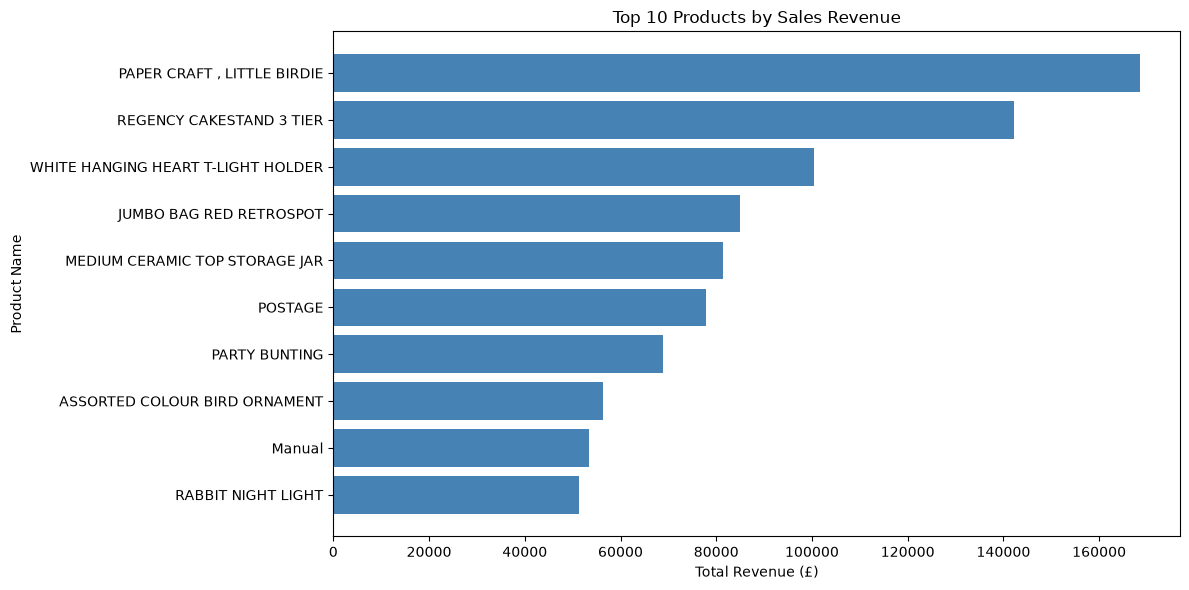

In [8]:
# Top 10 Products by Revenue

plt.figure(figsize=(12, 6))

plt.barh(
    top_products["Description"],
    top_products["Total_Revenue"],
    color="steelblue"
)

plt.xlabel("Total Revenue (£)")
plt.ylabel("Product Name")
plt.title("Top 10 Products by Sales Revenue")

plt.gca().invert_yaxis()
plt.tight_layout()

plt.show()

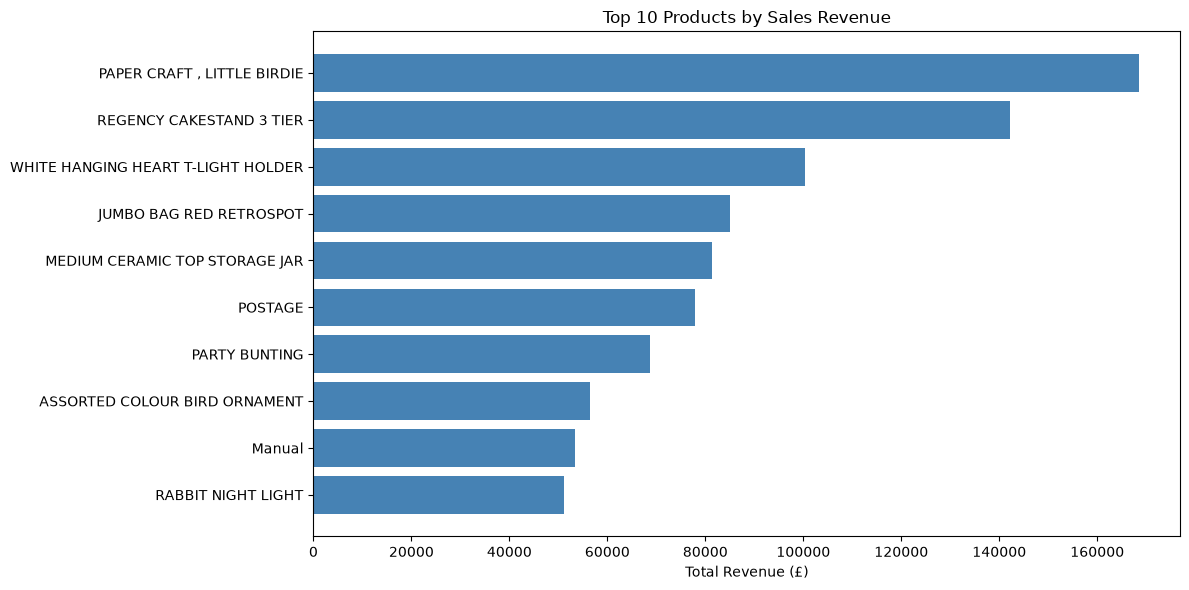

Chart saved successfully!


In [9]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.barh(
    top_products["Description"],
    top_products["Total_Revenue"],
    color="steelblue"
)

ax.invert_yaxis()
ax.set_xlabel("Total Revenue (£)")
ax.set_title("Top 10 Products by Sales Revenue")

fig.tight_layout()

chart_path = project_folder / "06_Documentation" / "top_10_products.png"

fig.savefig(chart_path, dpi=300, bbox_inches="tight")

plt.show()

print("Chart saved successfully!")

In [10]:
# Convert invoice dates to datetime
sales_df["InvoiceDate"] = pd.to_datetime(
    sales_df["InvoiceDate"],
    errors="coerce"
)

# Create monthly sales summary
monthly_sales = (
    sales_df.dropna(subset=["InvoiceDate"])
    .assign(
        Month=lambda x: x["InvoiceDate"].dt.to_period("M")
    )
    .groupby("Month")["Revenue"]
    .sum()
    .reset_index()
)

monthly_sales["Month"] = monthly_sales["Month"].astype(str)

print("MONTHLY SALES PERFORMANCE")
display(monthly_sales)

MONTHLY SALES PERFORMANCE


,Month,Revenue
0,2010-12,570422.730
1,2011-01,568101.310
2,2011-02,446084.920
3,2011-03,594081.760
4,2011-04,468374.331
5,2011-05,677355.150
6,2011-06,660046.050
7,2011-07,598962.901
8,2011-08,644051.040
9,2011-09,950690.202


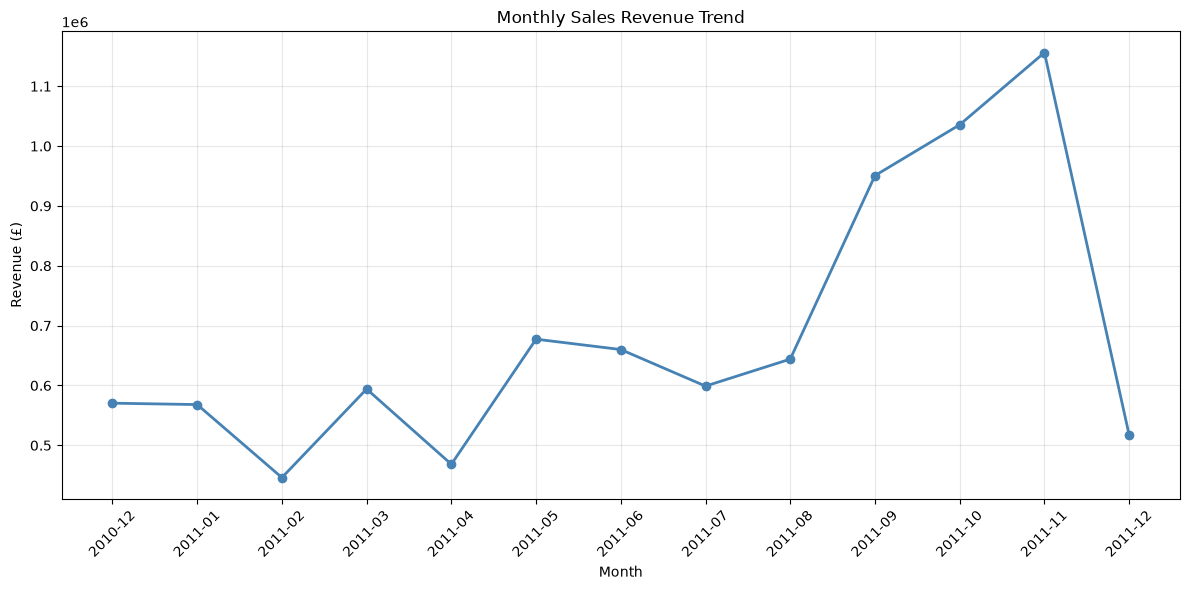

Monthly sales chart saved successfully!


In [11]:
# Monthly Revenue Trend Chart
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    monthly_sales["Month"],
    monthly_sales["Revenue"],
    marker="o",
    linewidth=2,
    color="steelblue"
)

ax.set_title("Monthly Sales Revenue Trend")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (£)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

# Save chart
chart_path = (
    project_folder /
    "06_Documentation" /
    "monthly_sales_trend.png"
)

fig.savefig(chart_path, dpi=300, bbox_inches="tight")

plt.show()

print("Monthly sales chart saved successfully!")

In [12]:
# Load existing customer segmentation data

rfm_path = (
    project_folder /
    "03_Python" /
    "rfm_customer_segments.csv"
)

rfm_df = pd.read_csv(rfm_path)

print("Customer Segmentation Data Loaded!")

print("\nAvailable Columns:")
print(rfm_df.columns.tolist())

print("\nFirst 5 Records:")
display(rfm_df.head())

Customer Segmentation Data Loaded!

Available Columns:
['CustomerID', 'Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score', 'CustomerSegment']

First 5 Records:


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,CustomerSegment
0,12346,326,1,77183.60,1,1,5,7,At Risk
1,12347,2,7,4310.00,5,5,5,15,VIP Customers
2,12348,75,4,1797.24,2,4,4,10,Loyal Customers
3,12349,19,1,1757.55,4,1,4,9,Regular Customers
4,12350,310,1,334.40,1,1,2,4,At Risk


In [13]:
# Find the customer segment column
segment_columns = [
    col for col in rfm_df.columns
    if "segment" in col.lower()
]

print("Segment columns:", segment_columns)

if segment_columns:
    segment_col = segment_columns[0]

    # Count customers in each segment
    segment_summary = (
        rfm_df[segment_col]
        .value_counts()
        .reset_index()
    )

    segment_summary.columns = [
        "Customer_Segment",
        "Customer_Count"
    ]

    segment_summary["Percentage"] = (
        segment_summary["Customer_Count"]
        / segment_summary["Customer_Count"].sum()
        * 100
    ).round(2)

    print("\nCUSTOMER SEGMENT ANALYSIS")
    display(segment_summary)
else:
    print("No segment column found.")
    print("Available columns:", rfm_df.columns.tolist())

Segment columns: ['CustomerSegment']

CUSTOMER SEGMENT ANALYSIS


,Customer_Segment,Customer_Count,Percentage
0,At Risk,1556,35.87
1,Loyal Customers,999,23.03
2,VIP Customers,942,21.72
3,Regular Customers,841,19.39


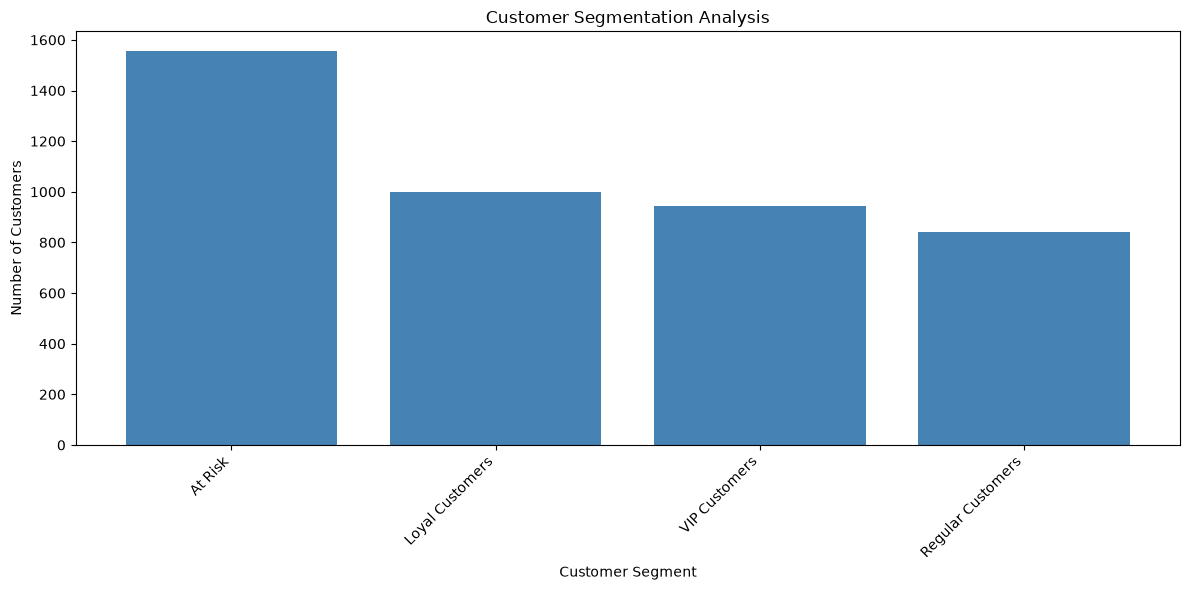

Customer segmentation chart saved successfully!


In [14]:
# Customer Segmentation Chart

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    segment_summary["Customer_Segment"].astype(str),
    segment_summary["Customer_Count"],
    color="steelblue"
)

ax.set_title("Customer Segmentation Analysis")
ax.set_xlabel("Customer Segment")
ax.set_ylabel("Number of Customers")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# Save chart
chart_path = (
    project_folder /
    "06_Documentation" /
    "customer_segmentation.png"
)

fig.savefig(chart_path, dpi=300, bbox_inches="tight")

plt.show()

print("Customer segmentation chart saved successfully!")

In [15]:
print("FINAL BUSINESS ANALYSIS SUMMARY")
print("=" * 45)

print("\nTOP 5 PRODUCTS BY REVENUE")
display(top_products.head(5))

print("\nMONTHLY SALES PERFORMANCE")
display(monthly_sales)

print("\nCUSTOMER SEGMENT DISTRIBUTION")
display(segment_summary)

print("\nKEY SALES KPIs")
print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Units Sold: {total_units:,.0f}")
print(f"Average Order Value: £{average_order_value:,.2f}")

FINAL BUSINESS ANALYSIS SUMMARY

TOP 5 PRODUCTS BY REVENUE


,Description,Total_Revenue,Units_Sold
0,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
1,REGENCY CAKESTAND 3 TIER,142264.75,12374
2,WHITE HANGING HEART T-LIGHT HOLDER,100392.10,36706
3,JUMBO BAG RED RETROSPOT,85040.54,46078
4,MEDIUM CERAMIC TOP STORAGE JAR,81416.73,77916



MONTHLY SALES PERFORMANCE


,Month,Revenue
0,2010-12,570422.730
1,2011-01,568101.310
2,2011-02,446084.920
3,2011-03,594081.760
4,2011-04,468374.331
5,2011-05,677355.150
6,2011-06,660046.050
7,2011-07,598962.901
8,2011-08,644051.040
9,2011-09,950690.202



CUSTOMER SEGMENT DISTRIBUTION


,Customer_Segment,Customer_Count,Percentage
0,At Risk,1556,35.87
1,Loyal Customers,999,23.03
2,VIP Customers,942,21.72
3,Regular Customers,841,19.39



KEY SALES KPIs
Total Revenue: £8,887,208.89
Total Orders: 18,532
Total Units Sold: 5,152,002
Average Order Value: £479.56
